**Installation et importation des bibliothèques**

In [44]:
%pip install kagglehub pandas numpy matplotlib seaborn scikit-learn joblib
%pip install --upgrade ipywidgets
%pip install --upgrade kagglehub

Note: you may need to restart the kernel to use updated packages.Requirement already satisfied: kagglehub in c:\users\lenovo\pycharmprojects\customer churn\.venv\lib\site-packages (0.3.13)




[notice] A new release of pip is available: 23.2.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [45]:
import os
import glob
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

**Chargement du dataset**

In [46]:
import kagglehub

path = kagglehub.dataset_download("blastchar/telco-customer-churn")

csv_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)

if not csv_files:
    raise FileNotFoundError("Aucun fichier CSV trouvé dans le dataset.")

print("Fichiers CSV trouvés :", csv_files)

df = pd.read_csv(csv_files[0])

print("Dataset chargé avec succès !")
print("Dimensions :", df.shape)

df.head()

Fichiers CSV trouvés : ['C:\\Users\\LENOVO\\.cache\\kagglehub\\datasets\\blastchar\\telco-customer-churn\\versions\\1\\WA_Fn-UseC_-Telco-Customer-Churn.csv']
Dataset chargé avec succès !
Dimensions : (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## **Compréhension des données (Data Understanding)**

In [47]:
print("Dimensions :", df.shape)

print("\nInformations générales :")
df.info()

print("\nValeurs manquantes :")
print(df.isnull().sum())

print("\nNombre de lignes dupliquées :")
print(df.duplicated().sum())

print("\nStatistiques descriptives :")
display(df.describe(include="all").T)

print(df["Churn"].value_counts())

print("\nPourcentages :")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

Dimensions : (7043, 21)

Informations générales :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   objec

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,3186-AJIEK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Churn
No     5174
Yes    1869
Name: count, dtype: int64

Pourcentages :
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


## **Nettoyage des données (Data Cleaning)**

In [48]:
df = df.copy()

# Convertir les charges totales en numérique
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Supprimer les éventuels doublons
df = df.drop_duplicates().reset_index(drop=True)

# Vérifier les données
print("Dimensions après nettoyage :", df.shape)
print("\nValeurs manquantes :")
print(df.isnull().sum().sum())

print("\nTypes des variables :")
print(df.dtypes)

Dimensions après nettoyage : (7043, 21)

Valeurs manquantes :
11

Types des variables :
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


## **Analyse exploratoire (EDA)**

### **5.1 Répartition de la variable cible**

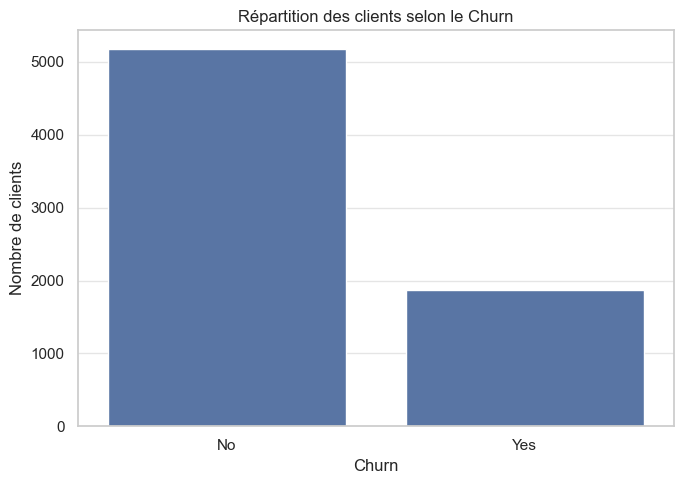

In [49]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Répartition des clients selon le Churn")
plt.xlabel("Churn")
plt.ylabel("Nombre de clients")
plt.tight_layout()
plt.show()

### **5.2 Taux de churn en pourcentage**

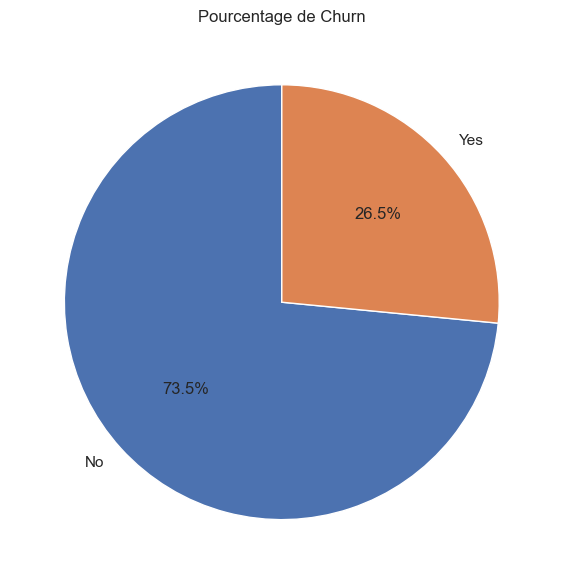

In [50]:
churn_rate = df["Churn"].value_counts(normalize=True) * 100

plt.figure(figsize=(6, 6))

plt.pie(
    churn_rate,
    labels=churn_rate.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Pourcentage de Churn")
plt.tight_layout()
plt.show()

### **5.3 Churn selon la durée d'ancienneté**

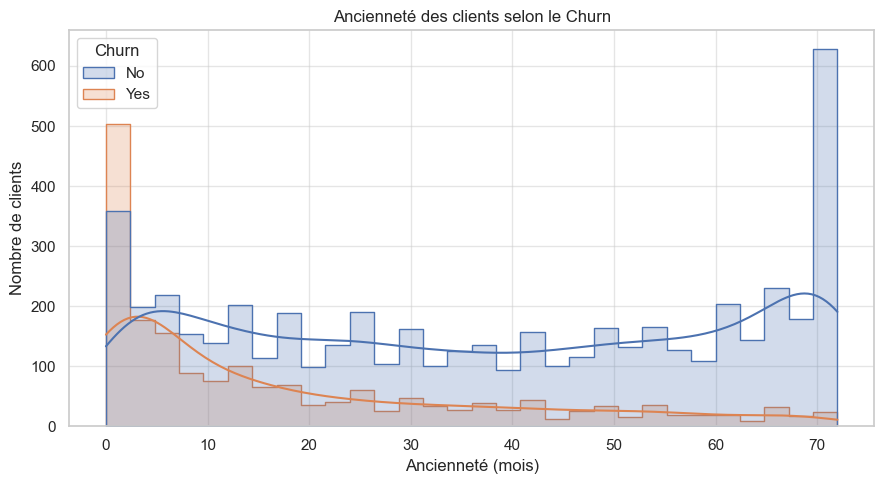

In [51]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    kde=True,
    element="step"
)

plt.title("Ancienneté des clients selon le Churn")
plt.xlabel("Ancienneté (mois)")
plt.ylabel("Nombre de clients")
plt.tight_layout()
plt.show()

### **5.4 Churn selon le type de contrat**

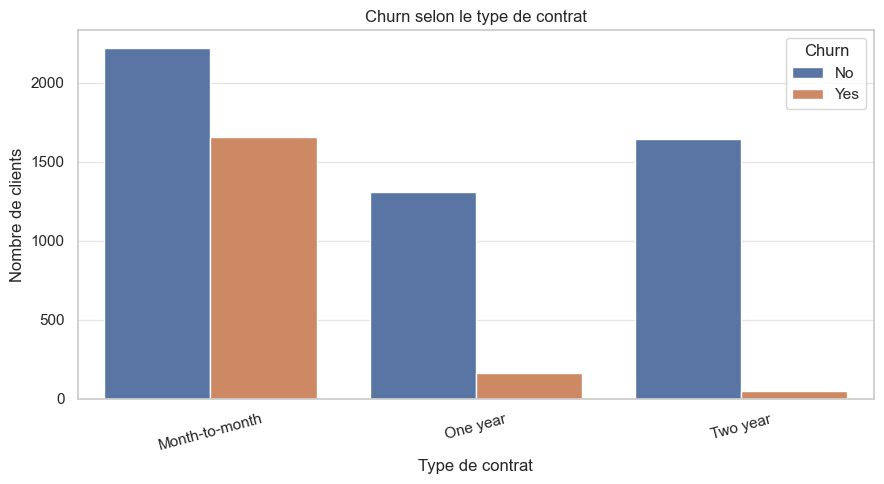

In [52]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Churn selon le type de contrat")
plt.xlabel("Type de contrat")
plt.ylabel("Nombre de clients")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### **5.5 Churn selon les frais mensuels**

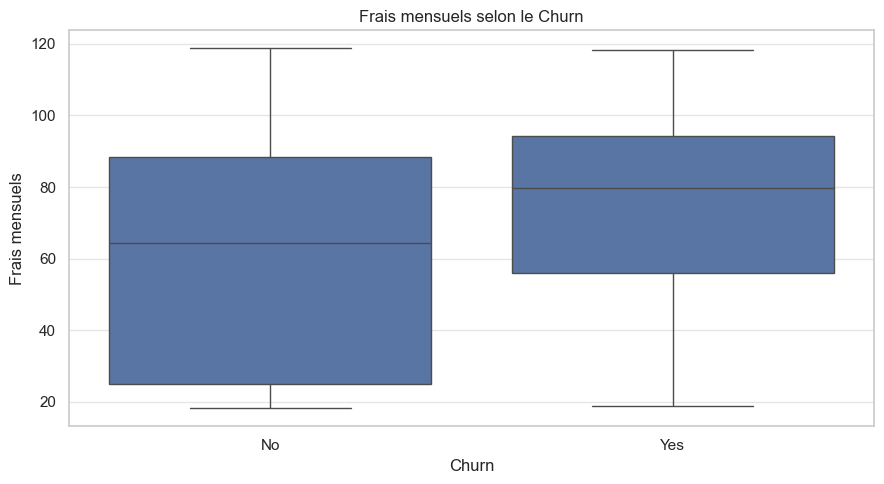

In [53]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Frais mensuels selon le Churn")
plt.xlabel("Churn")
plt.ylabel("Frais mensuels")
plt.tight_layout()
plt.show()

### **5.6 Churn selon le mode de paiement**

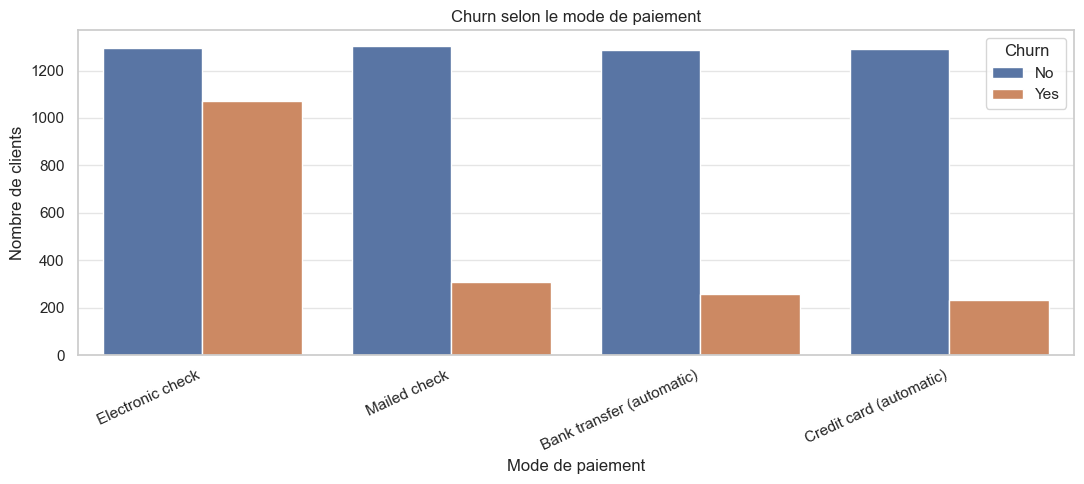

In [54]:
plt.figure(figsize=(11, 5))

sns.countplot(
    data=df,
    x="PaymentMethod",
    hue="Churn"
)

plt.title("Churn selon le mode de paiement")
plt.xlabel("Mode de paiement")
plt.ylabel("Nombre de clients")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


## **6. Préparation des données (Data Preprocessing) & Construire le pipeline de preprocessing**

In [55]:
# Séparer les variables explicatives et la cible
X = df.drop(columns=["Churn", "customerID"], errors="ignore")

y = df["Churn"].map({"No": 0, "Yes": 1})

# Vérifier que la cible est valide
assert y.notna().all(), "La variable cible contient des valeurs inattendues."

# Identifier les colonnes numériques et catégorielles
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Variables numériques :", numeric_features)
print("\nVariables catégorielles :", categorical_features)

# Division des données
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\nTaille de X_train :", X_train.shape)
print("Taille de X_test  :", X_test.shape)
print("Taille de y_train :", y_train.shape)
print("Taille de y_test  :", y_test.shape)


# Pipeline numérique
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Pipeline catégoriel
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combiner les transformations
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

Variables numériques : ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Variables catégorielles : ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Taille de X_train : (5634, 19)
Taille de X_test  : (1409, 19)
Taille de y_train : (5634,)
Taille de y_test  : (1409,)



## **7. Entraînement des modèles (Model Training)**

In [56]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

trained_models = {}

for name, classifier in models.items():

    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    model.fit(X_train, y_train)

    trained_models[name] = model

    print(f"{name} entraîné avec succès !")

Logistic Regression entraîné avec succès !
Random Forest entraîné avec succès !



## **8. Évaluation des modèles (Model Evaluation)**

In [57]:
results = []
predictions = {}

for name, model in trained_models.items():

    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    predictions[name] = {
        "y_pred": y_pred,
        "y_proba": y_proba
    }

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_proba)
    })

results_df = pd.DataFrame(results).set_index("Model")

display(results_df.round(4))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8413
Random Forest,0.7828,0.6181,0.4759,0.5378,0.8220


### **8.1 Comparaison visuelle**

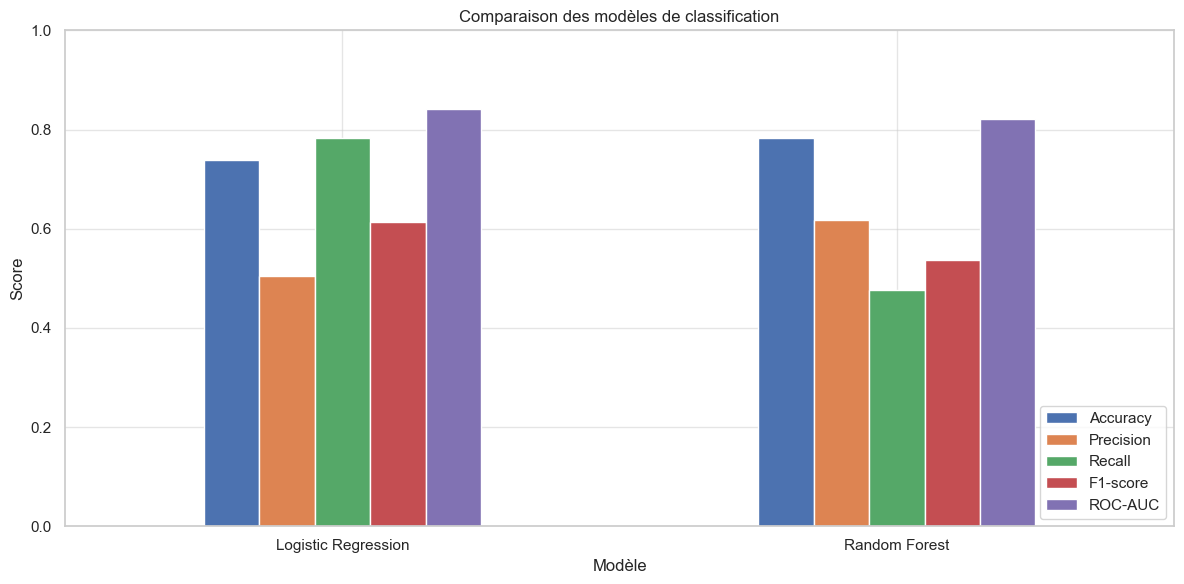

In [58]:
results_df.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Comparaison des modèles de classification")
plt.ylabel("Score")
plt.xlabel("Modèle")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### **8.2 Matrices de confusion**

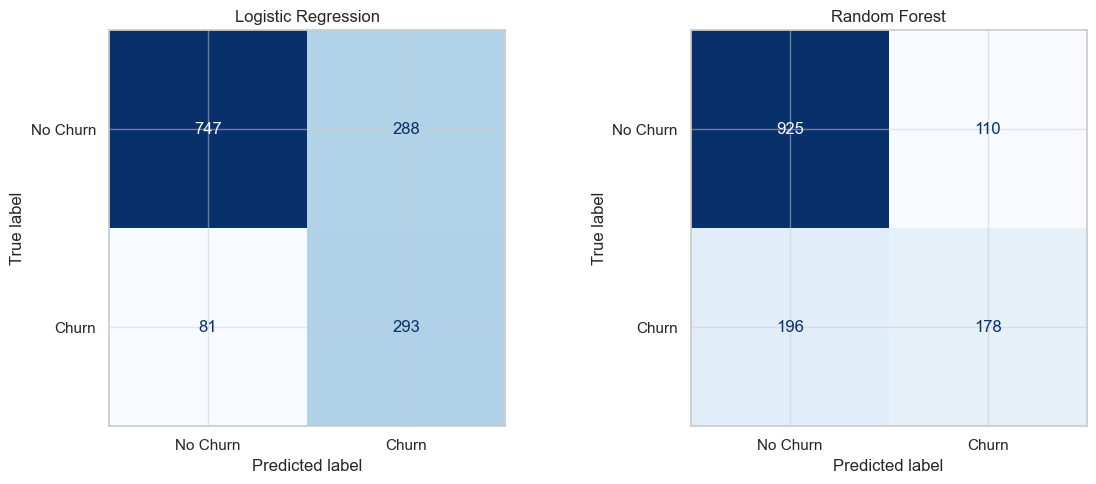

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, model) in zip(axes, trained_models.items()):

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions[name]["y_pred"],
        labels=[0, 1],
        display_labels=["No Churn", "Churn"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

### **8.3 Rapports de classification**

In [60]:
for name in trained_models:

    print("=" * 55)
    print(name)
    print("=" * 55)

    print(
        classification_report(
            y_test,
            predictions[name]["y_pred"],
            labels=[0, 1],
            target_names=["No Churn", "Churn"],
            zero_division=0
        )
    )

Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

Random Forest
              precision    recall  f1-score   support

    No Churn       0.83      0.89      0.86      1035
       Churn       0.62      0.48      0.54       374

    accuracy                           0.78      1409
   macro avg       0.72      0.68      0.70      1409
weighted avg       0.77      0.78      0.77      1409



### **8.4 Courbes ROC**

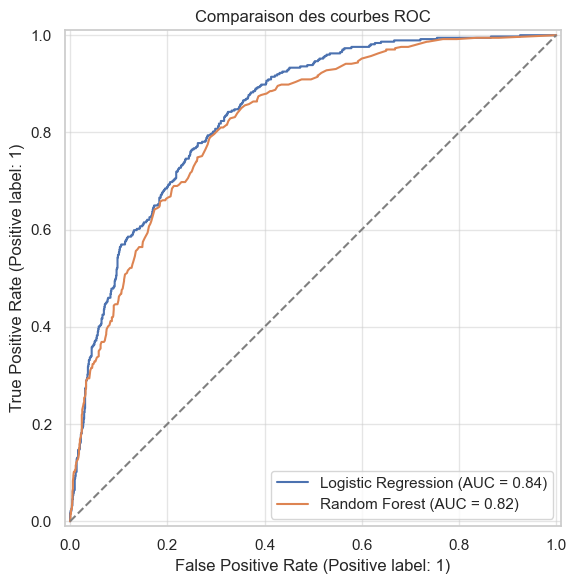

In [61]:
fig, ax = plt.subplots(figsize=(8, 6))

for name in trained_models:

    RocCurveDisplay.from_predictions(
        y_test,
        predictions[name]["y_proba"],
        name=name,
        ax=ax
    )

ax.plot([0, 1], [0, 1], linestyle="--", color="gray")

ax.set_title("Comparaison des courbes ROC")
plt.tight_layout()
plt.show()

### **9. Identifier les variables importantes (Feature Importance)**

Meilleur modèle selon le ROC-AUC : Logistic Regression


,Feature,Importance
1,num__tenure,1.123589
38,cat__Contract_Two year,0.781257
16,cat__InternetService_Fiber optic,0.705336
2,num__MonthlyCharges,0.663581
36,cat__Contract_Month-to-month,0.663399
15,cat__InternetService_DSL,0.621009
3,num__TotalCharges,0.457211
35,cat__StreamingMovies_Yes,0.274978
25,cat__DeviceProtection_No internet service,0.274568
17,cat__InternetService_No,0.274568


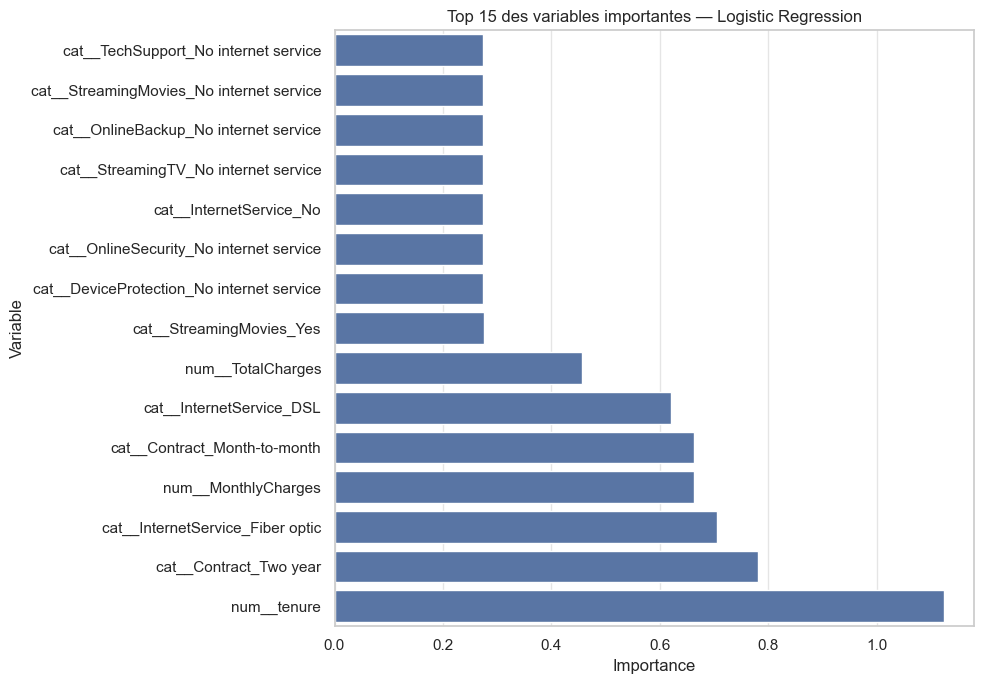

In [62]:
# Sélection du meilleur modèle selon le ROC-AUC
best_model_name = results_df["ROC-AUC"].idxmax()
best_model = trained_models[best_model_name]

print("Meilleur modèle selon le ROC-AUC :", best_model_name)

# Récupérer les noms des variables après transformation
feature_names = best_model.named_steps[
    "preprocessor"
].get_feature_names_out()

classifier = best_model.named_steps["classifier"]

# Extraire les importances
if isinstance(classifier, LogisticRegression):
    importances = np.abs(classifier.coef_[0])
else:
    importances = classifier.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(15))

top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title(f"Top 15 des variables importantes — {best_model_name}")
plt.xlabel("Importance")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()


### **10. Tester le modèle sur des clients**

In [63]:
sample = X_test.head(10)

sample_proba = best_model.predict_proba(sample)[:, 1]
sample_pred = best_model.predict(sample)

prediction_df = pd.DataFrame({
    "Churn réel": y_test.loc[sample.index].map({
        0: "No",
        1: "Yes"
    }),
    "Probabilité de Churn (%)": (sample_proba * 100).round(2),
    "Churn prédit": pd.Series(
        sample_pred,
        index=sample.index
    ).map({
        0: "No",
        1: "Yes"
    })
}, index=sample.index)

display(prediction_df)

,Churn réel,Probabilité de Churn (%),Churn prédit
437,No,11.55,No
2280,No,85.31,Yes
2235,No,14.68,No
4460,No,66.07,Yes
3761,No,6.04,No
5748,No,80.61,Yes
3568,No,69.85,Yes
2976,No,29.41,No
5928,No,0.93,No
1639,Yes,65.26,Yes



## **11. Sauvegarder le modèle et Recharger le modèle plus tard**

In [64]:
os.makedirs("../models", exist_ok=True)

model_path = "../models/customer_churn_model.joblib"

joblib.dump(best_model, model_path)

print("Modèle sauvegardé dans :", model_path)

loaded_model = joblib.load("../models/customer_churn_model.joblib")

new_predictions = loaded_model.predict(X_test.head(5))

print("Prédictions :", new_predictions)

Modèle sauvegardé dans : ../models/customer_churn_model.joblib
Prédictions : [0 1 0 1 0]



## **12. Conclusion du projet**

In [65]:
print("CUSTOMER CHURN PREDICTION — PROJECT SUMMARY")
print("=" * 50)

print(f"Nombre de clients : {len(df)}")
print(f"Nombre de variables explicatives : {X.shape[1]}")
print(f"Taux de Churn : {y.mean() * 100:.2f}%")

print("\nRésultats des modèles :")
display(results_df.round(4))

print(f"\nMeilleur modèle selon ROC-AUC : {best_model_name}")
print(f"ROC-AUC : {results_df.loc[best_model_name, 'ROC-AUC']:.4f}")
print(f"Recall : {results_df.loc[best_model_name, 'Recall']:.4f}")
print(f"F1-score : {results_df.loc[best_model_name, 'F1-score']:.4f}")

print("\nProjet terminé : entraînement, évaluation et sauvegarde.")

CUSTOMER CHURN PREDICTION — PROJECT SUMMARY
Nombre de clients : 7043
Nombre de variables explicatives : 19
Taux de Churn : 26.54%

Résultats des modèles :


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8413
Random Forest,0.7828,0.6181,0.4759,0.5378,0.8220



Meilleur modèle selon ROC-AUC : Logistic Regression
ROC-AUC : 0.8413
Recall : 0.7834
F1-score : 0.6136

Projet terminé : entraînement, évaluation et sauvegarde.
